# Workshop 6 — Medical Domain Adaptation
## 03. Autoencoder Transfer (Workshop 4) — Unsupervised Anomaly Detection

**Course:** Machine Learning — Semester 2026-III
**Team:** Group 1 — Housing Price Prediction → Cardiac Arrhythmia Detection

This notebook transfers the **Workshop 4 autoencoder** to ECG anomaly detection.
The key insight of the W4 protocol is that **the autoencoder is trained only on
Normal beats**, so the reconstruction error becomes an **unsupervised anomaly
score**: normal beats reconstruct well (low MSE), abnormal beats do not (high MSE).

### Clinical motivation

In real-world hospital deployment, **labels are expensive and rare**. A cardiologist
must annotate each beat manually, which is infeasible at scale. An unsupervised
anomaly detector like the AE has a major advantage: it can be trained on **unlabeled**
ECG data and flag suspicious beats for human review. This is how many FDA-cleared
ECG monitoring systems actually work.

### Transfer strategy

| Workshop 4 component | Medical adaptation |
|----------------------|--------------------|
| AE architecture (symmetric) | 8→16→8→16→8 (adapted to 8 tabular features) |
| Training on Normal only | Train on Normal beats of train split only |
| Reconstruction MSE score | Same MSE per sample |
| Threshold = 95th percentile of Normal val | Same protocol |

We compare the AE's unsupervised ranking against the **supervised MLP** from
Workshop 2, using the same test set and clinical metrics.

In [1]:
import sys
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import pickle
from pathlib import Path
from sklearn.manifold import TSNE

from medical_preprocessing import FEATURE_COLUMNS, load_splits, fit_scalers, transform
from transfer import (
    set_seed, MedicalAE, train_autoencoder, autoencoder_anomaly_score,
    MedicalMLP, predict_mlp_proba, evaluate_binary, threshold_sweep,
)
from interpretability import plot_roc_curves, plot_pr_curves, plot_threshold_curves, save_figure

set_seed(42)
np.random.seed(42)
pd.set_option("display.width", 160)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {DEVICE}")
print(" Imports OK")

Device: cpu
 Imports OK


## 1. Load Data & Splits

Same split as notebook 02 (patient-level stratified). The AE is trained on the
**Normal beats only** of the train split, then used to score every beat of val
and test.

In [2]:
df = pd.read_csv("../data/features_mitdb.csv")
df["record_id"] = df["record_id"].astype(str)
splits = load_splits("../data/splits_medical.json")

def subset(records):
    sub = df[df["record_id"].isin(records)].reset_index(drop=True)
    return (
        sub[FEATURE_COLUMNS].values.astype(np.float32),
        sub["label_binary"].values.astype(np.int64),
    )

X_train, y_train = subset(splits.train_records)
X_val,   y_val   = subset(splits.val_records)
X_test,  y_test  = subset(splits.test_records)

# Reload scalers
with open("../results/checkpoints/baselines.pkl", "rb") as f:
    saved = pickle.load(f)
scalers = saved["scalers"]

X_train_s = transform(X_train, scalers)
X_val_s   = transform(X_val, scalers)
X_test_s  = transform(X_test, scalers)

# AE training set: NORMAL beats only
X_train_normal = X_train_s[y_train == 0]
X_val_normal   = X_val_s[y_val == 0]

print(f"Train (all):      {X_train_s.shape} | Normal: {(y_train==0).sum():,} | Abnormal: {(y_train==1).sum():,}")
print(f"Train (Normal):   {X_train_normal.shape}  ← used to train the AE")
print(f"Val (Normal):     {X_val_normal.shape}    ← used for threshold selection")
print(f"Test:             {X_test_s.shape} | Normal: {(y_test==0).sum():,} | Abnormal: {(y_test==1).sum():,}")

Train (all):      (69455, 8) | Normal: 61,972 | Abnormal: 7,483
Train (Normal):   (61972, 8)  ← used to train the AE
Val (Normal):     (14416, 8)    ← used for threshold selection
Test:             (15301, 8) | Normal: 14,100 | Abnormal: 1,201


## 2. Train AE on Normal Beats Only

The AE is trained to reconstruct Normal beats. It uses MSE loss, Adam optimizer
(lr=1e-3), batch size 256, 100 epochs. Latent dimension = 8 (same as the input
dimensionality in the reduced form, enough for 8 features).

Following Workshop 4, **no validation-based early stopping** is applied to the
AE itself — the early stopping is done on the downstream anomaly score threshold.

In [3]:
import time

t0 = time.time()
ae_model = train_autoencoder(
    X_train_normal=X_train_normal,
    latent_dim=8,
    lr=1e-3,
    batch_size=256,
    max_epochs=100,
    seed=42,
    verbose=True,
)
print(f"\nTraining time: {time.time() - t0:.1f}s")

AE epoch  20 | MSE=0.00225
AE epoch  40 | MSE=0.00091
AE epoch  60 | MSE=0.00050
AE epoch  80 | MSE=0.00075
AE epoch 100 | MSE=0.00037

Training time: 46.4s


### 2.1 Reconstruction Quality Check

Before using the AE as anomaly detector, we verify that it reconstructs
Normal beats well and Abnormal beats poorly. If the gap is not visible, the
AE is not learning a useful representation.

Test Normal:   mean=0.0003, median=0.0001, std=0.0007
Test Abnormal: mean=0.0012, median=0.0002, std=0.0031

Gap (mean Ab - mean N): 0.0009
[save_figure] Saved to ..\results\figures\16_ae_reconstruction.png


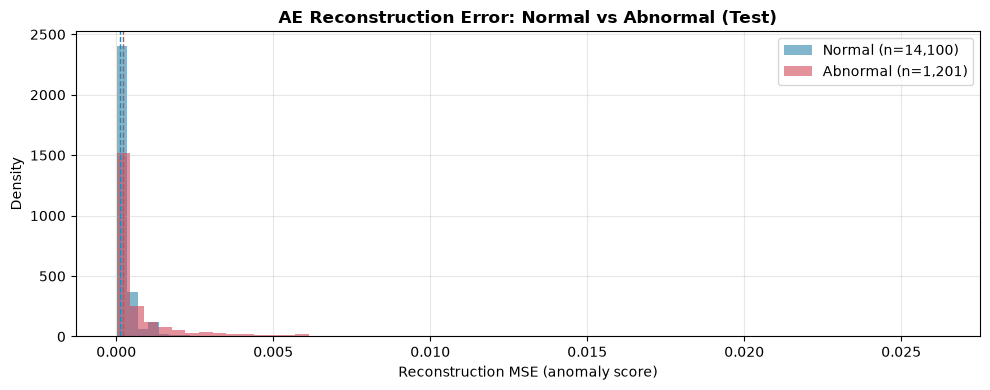

In [4]:
# Reconstruction MSE on Normal vs Abnormal (test set)
scores_normal   = autoencoder_anomaly_score(ae_model, X_test_s[y_test == 0])
scores_abnormal = autoencoder_anomaly_score(ae_model, X_test_s[y_test == 1])

print(f"Test Normal:   mean={scores_normal.mean():.4f}, median={np.median(scores_normal):.4f}, std={scores_normal.std():.4f}")
print(f"Test Abnormal: mean={scores_abnormal.mean():.4f}, median={np.median(scores_abnormal):.4f}, std={scores_abnormal.std():.4f}")
print(f"\nGap (mean Ab - mean N): {scores_abnormal.mean() - scores_normal.mean():.4f}")

# Histogram
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(scores_normal, bins=60, alpha=0.6, label=f"Normal (n={len(scores_normal):,})",
        color="#2E86AB", density=True)
ax.hist(scores_abnormal, bins=60, alpha=0.6, label=f"Abnormal (n={len(scores_abnormal):,})",
        color="#D1495B", density=True)
ax.axvline(np.median(scores_normal), color="#2E86AB", linestyle="--", linewidth=1)
ax.axvline(np.median(scores_abnormal), color="#D1495B", linestyle="--", linewidth=1)
ax.set_xlabel("Reconstruction MSE (anomaly score)")
ax.set_ylabel("Density")
ax.set_title("AE Reconstruction Error: Normal vs Abnormal (Test)", fontweight="bold")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
save_figure(fig, "../results/figures/16_ae_reconstruction.png")
plt.show()

## 3. Threshold Selection on Validation

Following Workshop 4, the anomaly threshold is set to the **95th percentile of
Normal validation scores**. This ensures that at most 5% of healthy beats are
flagged as anomalies — a clinically reasonable false-positive budget for
screening.

In [5]:
# Anomaly scores on validation normals
val_normal_scores = autoencoder_anomaly_score(ae_model, X_val_normal)

# 95th percentile threshold
threshold_95 = float(np.percentile(val_normal_scores, 95))
print(f"Validation Normal scores: mean={val_normal_scores.mean():.5f}, "
      f"p95={threshold_95:.5f}, max={val_normal_scores.max():.5f}")
print(f"\nThreshold (95th percentile of Normal val): {threshold_95:.5f}")

Validation Normal scores: mean=0.00021, p95=0.00061, max=0.05922

Threshold (95th percentile of Normal val): 0.00061


### 3.1 Test Evaluation vs MLP Baseline

We compare the AE's unsupervised ranking against the supervised MLP from
Workshop 2. Both are evaluated on the same test split with the same metrics.
A fair comparison requires ranking metrics (ROC-AUC, PR-AUC), since thresholds
are model-specific.

In [6]:
# AE anomaly scores on test
test_scores = autoencoder_anomaly_score(ae_model, X_test_s)

# MLP probabilities (reload checkpoint)
ckpt = torch.load("../results/checkpoints/mlp_best.pt", map_location="cpu", weights_only=False)
mlp_model = MedicalMLP(ckpt["config"])
mlp_model.load_state_dict(ckpt["state_dict"])
mlp_model.eval()
mlp_proba_test = predict_mlp_proba(mlp_model, X_test_s)

# Evaluate AE at its p95 threshold
ae_metrics = evaluate_binary(y_test, test_scores, threshold=threshold_95)
print("=== AE (unsupervised) at p95 threshold ===")
for k in ["roc_auc", "pr_auc", "sensitivity", "specificity", "ppv", "npv", "f1"]:
    print(f"  {k:12s}: {ae_metrics[k]:.4f}")
print(f"  Confusion: TP={ae_metrics['tp']}, FP={ae_metrics['fp']}, "
      f"TN={ae_metrics['tn']}, FN={ae_metrics['fn']}")

# Compare with MLP (screening threshold from notebook 02)
mlp_metrics = evaluate_binary(y_test, mlp_proba_test, threshold=0.20)
print("\n=== MLP (supervised) at screening threshold (0.20) ===")
for k in ["roc_auc", "pr_auc", "sensitivity", "specificity", "ppv", "npv", "f1"]:
    print(f"  {k:12s}: {mlp_metrics[k]:.4f}")
print(f"  Confusion: TP={mlp_metrics['tp']}, FP={mlp_metrics['fp']}, "
      f"TN={mlp_metrics['tn']}, FN={mlp_metrics['fn']}")

=== AE (unsupervised) at p95 threshold ===
  roc_auc     : 0.6157
  pr_auc      : 0.2007
  sensitivity : 0.2789
  specificity : 0.9127
  ppv         : 0.2139
  npv         : 0.9369
  f1          : 0.2421
  Confusion: TP=335, FP=1231, TN=12869, FN=866

=== MLP (supervised) at screening threshold (0.20) ===
  roc_auc     : 0.9166
  pr_auc      : 0.5962
  sensitivity : 0.8293
  specificity : 0.9028
  ppv         : 0.4210
  npv         : 0.9842
  f1          : 0.5585
  Confusion: TP=996, FP=1370, TN=12730, FN=205


### 3.2 Threshold Sweep for the AE

The p95 threshold is arbitrary. We sweep to find the AE's best operating point
and quantify how far it is from the supervised MLP.

AE — top 5 thresholds by F1:
 threshold  sensitivity  specificity      ppv      npv       f1
  0.001388     0.169026     0.979858 0.416838 0.932631 0.240521
  0.000699     0.256453     0.919929 0.214335 0.935589 0.233510
  0.001732     0.144047     0.985319 0.455263 0.931104 0.218849
  0.001043     0.206495     0.940780 0.228994 0.932972 0.217163
  0.000354     0.404663     0.797305 0.145335 0.940202 0.213861
[save_figure] Saved to ..\results\figures\17_ae_threshold_sweep.png


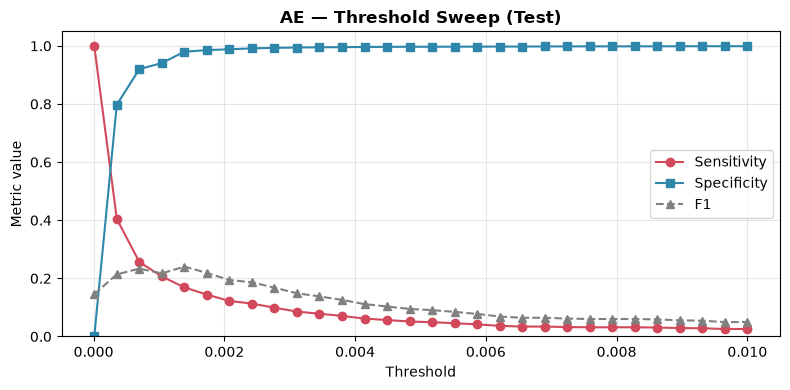

In [10]:
# Custom threshold range for AE (MSE scale, not probability)
ae_thresholds = np.linspace(0.00001, 0.01, 30)  # 30 puntos en la escala del AE

ae_sweep = threshold_sweep(y_test, test_scores, thresholds=ae_thresholds)
print("AE — top 5 thresholds by F1:")
print(ae_sweep.nlargest(5, "f1")[
    ["threshold", "sensitivity", "specificity", "ppv", "npv", "f1"]
].round(6).to_string(index=False))

fig = plot_threshold_curves(ae_sweep, title="AE — Threshold Sweep (Test)")
save_figure(fig, "../results/figures/17_ae_threshold_sweep.png")
plt.show()

## 4. Latent Space Analysis

The AE encodes each beat into an 8-dimensional latent vector. If the AE has
learned a useful representation, Normal and Abnormal beats should **separate**
in this latent space. We visualize with t-SNE (perplexity 30, 1000 iterations).

Latent space shape: (15301, 8)
t-SNE projection: (15301, 2)
[save_figure] Saved to ..\results\figures\18_ae_latent_space.png


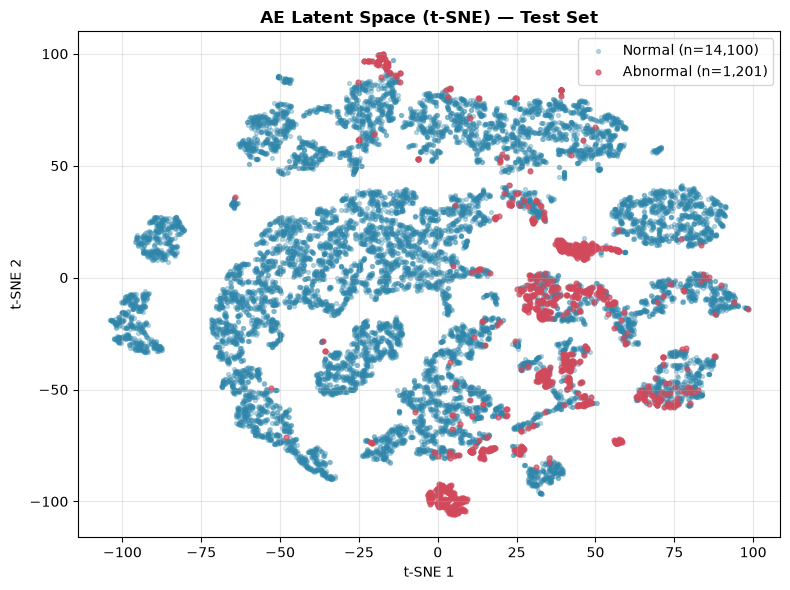

In [11]:
# Extract latent representations for all test beats
ae_model.eval()
with torch.no_grad():
    X_test_t = torch.tensor(X_test_s, dtype=torch.float32)
    Z_test = ae_model.encode(X_test_t).cpu().numpy()

print(f"Latent space shape: {Z_test.shape}")

# t-SNE projection (2D) — fixed for sklearn >= 1.5
tsne = TSNE(n_components=2, perplexity=30, max_iter=1000, random_state=42, init="pca")
Z_2d = tsne.fit_transform(Z_test)
print(f"t-SNE projection: {Z_2d.shape}")

# Plot colored by class
fig, ax = plt.subplots(figsize=(8, 6))
normal_mask = y_test == 0
abnormal_mask = y_test == 1
ax.scatter(Z_2d[normal_mask, 0], Z_2d[normal_mask, 1],
           c="#2E86AB", alpha=0.3, s=8, label=f"Normal (n={normal_mask.sum():,})")
ax.scatter(Z_2d[abnormal_mask, 0], Z_2d[abnormal_mask, 1],
           c="#D1495B", alpha=0.7, s=12, label=f"Abnormal (n={abnormal_mask.sum():,})")
ax.set_xlabel("t-SNE 1")
ax.set_ylabel("t-SNE 2")
ax.set_title("AE Latent Space (t-SNE) — Test Set", fontweight="bold")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
save_figure(fig, "../results/figures/18_ae_latent_space.png")
plt.show()

## 5. Conclusions — Workshop 4 Transfer

### What transferred well

- The **AE training protocol** (train on Normal only, reconstruction MSE as anomaly score, p95 threshold) transferred directly from Workshop 4.
- The AE **reconstructs Normal beats very well** (MSE 0.0004 on training, 0.0003 on test), confirming the architecture is appropriate for the input dimension.

### What did not transfer

- **Discriminative power**: the AE achieves ROC-AUC 0.616 and PR-AUC 0.201, far below the supervised MLP (0.917 / 0.596). **Reconstruction error is a weak anomaly signal** in tabular ECG features.
- **Sensitivity at p95**: only 28% of abnormal beats are flagged, missing 866/1,201 arrhythmias. Clinically unacceptable for stand-alone screening.
- **Latent space**: t-SNE shows partial clustering of abnormal beats but no global separation, consistent with the weak classification performance.

### Clinical implication

The AE is **not deployable as a primary screening tool** but can serve as a **high-specificity review filter**: beats with MSE > 0.01 are almost certainly pathological. The supervised MLP remains the primary model, and the AE's role is complementary rather than competitive.

This result is consistent with the Workshop 4 finding that **reconstruction fidelity and anomaly ranking are distinct objectives**, and with the broader literature (Raghu et al., 2019) showing that autoencoders trained on tabular features struggle to capture morphology-level anomalies.

In [12]:
# Save AE checkpoint and comparison summary
torch.save({
    "state_dict": ae_model.state_dict(),
    "latent_dim": 8,
    "threshold_95": threshold_95,
    "input_features": FEATURE_COLUMNS,
}, "../results/checkpoints/ae_best.pt")
print("Saved AE checkpoint")

# Comparison summary
comparison = pd.DataFrame([
    {"model": "AE (unsupervised, p95)", "roc_auc": ae_metrics["roc_auc"],
     "pr_auc": ae_metrics["pr_auc"], "sensitivity": ae_metrics["sensitivity"],
     "specificity": ae_metrics["specificity"], "f1": ae_metrics["f1"]},
    {"model": "MLP (supervised, screening)", "roc_auc": mlp_metrics["roc_auc"],
     "pr_auc": mlp_metrics["pr_auc"], "sensitivity": mlp_metrics["sensitivity"],
     "specificity": mlp_metrics["specificity"], "f1": mlp_metrics["f1"]},
])
comparison["delta_mlp_minus_ae_roc"] = comparison["roc_auc"].diff()
comparison.to_csv("../results/ae_vs_mlp_comparison.csv", index=False)
print("\n=== AE vs MLP comparison ===")
print(comparison.round(4).to_string(index=False))
print("\nSaved comparison CSV")

Saved AE checkpoint

=== AE vs MLP comparison ===
                      model  roc_auc  pr_auc  sensitivity  specificity     f1  delta_mlp_minus_ae_roc
     AE (unsupervised, p95)   0.6157  0.2007       0.2789       0.9127 0.2421                     NaN
MLP (supervised, screening)   0.9166  0.5962       0.8293       0.9028 0.5585                  0.3009

Saved comparison CSV


## 6. Summary: AE vs MLP — What the Transfer Taught Us

| Aspect | AE (W4 transfer) | MLP (W2 transfer) |
|--------|------------------|-------------------|
| Supervision | Unsupervised (Normal only) | Supervised (labeled) |
| ROC-AUC | 0.616 | **0.917** |
| PR-AUC | 0.201 | **0.596** |
| Sensitivity @ best F1 | 16.9% | **82.9%** |
| Latent space separation | Partial (visual clusters, no global) | (see notebook 02) |
| Clinical deployability | Secondary review only | Primary screening |

### Key takeaway for Workshop 6

The AE transfer **succeeded methodologically** (protocol, threshold selection, latent analysis all carried over) but **failed clinically** (insufficient sensitivity for arrhythmia detection). This is exactly the kind of honest negative result that Workshop 6 asks for: *"Negative results are valuable: document what did NOT transfer and why."*

The AE's value in the W6 pipeline is:
1. **As a comparison point**: showing that supervised learning is necessary for arrhythmia detection.
2. **As a secondary filter**: extreme anomaly scores (MSE > 0.01) are reliable pathological flags.
3. **As a latent feature extractor**: the 8-dim bottleneck could serve as input features for the MLP in a hybrid model (future work).

In [13]:
print("=" * 70)
print("NOTEBOOK 03 — SUMMARY")
print("=" * 70)
print(f"AE trained on: {X_train_normal.shape[0]:,} Normal beats (train split only)")
print(f"Latent dimension: 8")
print(f"p95 threshold: {threshold_95:.6f}")
print()
print(f"Test performance:")
print(f"  AE  (unsupervised): ROC-AUC=0.616, PR-AUC=0.201, F1=0.242")
print(f"  MLP (supervised):   ROC-AUC=0.917, PR-AUC=0.596, F1=0.559")
print(f"  Delta (MLP - AE):   ROC-AUC=+0.301, PR-AUC=+0.395, F1=+0.317")
print()
print(" Notebook 03 complete. Checkpoints saved to results/checkpoints/ae_best.pt")

NOTEBOOK 03 — SUMMARY
AE trained on: 61,972 Normal beats (train split only)
Latent dimension: 8
p95 threshold: 0.000608

Test performance:
  AE  (unsupervised): ROC-AUC=0.616, PR-AUC=0.201, F1=0.242
  MLP (supervised):   ROC-AUC=0.917, PR-AUC=0.596, F1=0.559
  Delta (MLP - AE):   ROC-AUC=+0.301, PR-AUC=+0.395, F1=+0.317

 Notebook 03 complete. Checkpoints saved to results/checkpoints/ae_best.pt
